# Member 2 — Task 2: Class Imbalance Handling for LightGBM

**Role:** Member 2 (LightGBM Lead)  
**Branch:** `feat/m2-task2-lgbm-imbalance`  
**Primary Metric:** Out-of-Fold **AUPRC** (`nn_data_pipeline.evaluate_auprc`)  
**Dataset:** `processed_data/train_lgbm.parquet` (`699,960` rows, `35` features, Fraud rate `1.6700%`, Imbalance Ratio $\approx 58.88$).

### Design Principles & Constraints
1. **No SMOTE / ADASYN:** Synthetic interpolation across binary risk flags (`is_foreign_transaction`, `used_vpn`, `ip_country_mismatch`, `is_ai_generated_scam_attempt`, etc.) introduces unrealistic fractional noise and degrades decision tree split precision.
2. **Strict Zero Data Leakage:** Every fold-dependent `scale_pos_weight` is computed strictly from `y_train` inside each training fold (`fold != k`).
3. **Calibration Awareness for Phase 3 Blending:** Beyond AUPRC, we inspect predicted probability calibration (mean predicted probability vs. true base rate `1.67%`) because strongly distorted probability scales require extra care when blending with Member 3's Neural Network.

## 1. Load Data & Define Controlled Imbalance Experiment Matrix

In [1]:
import os, sys
PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import brier_score_loss, log_loss, precision_recall_curve

from lgbm.lgbm_pipeline import (
    TARGET_COL,
    get_default_lgbm_params,
    load_lgbm_datasets,
    run_lgbm_cv,
)

sns.set_theme(style="whitegrid")

train_df, test_df, feature_cols, cat_cols = load_lgbm_datasets()
y_true = train_df[TARGET_COL].to_numpy(dtype=np.int64)
base_rate = float(y_true.mean())
ir = float((y_true == 0).sum() / (y_true == 1).sum())

print(f"Dataset loaded: {train_df.shape} | Features: {len(feature_cols)}")
print(f"Base Fraud Rate: {base_rate * 100:.4f}% | IR = {ir:.2f} | sqrt(IR) = {np.sqrt(ir):.2f}")

experiments = [
    ("EXP-2.1", "Unweighted (spw=1.0)", {"is_unbalance": False}, "none"),
    ("EXP-2.2", "is_unbalance=True", {"is_unbalance": True}, None),
    ("EXP-2.3", "Balanced (spw=N_neg/N_pos ~58.88)", {}, "balanced"),
    ("EXP-2.4", "Sqrt Balanced (spw=sqrt(IR) ~7.67)", {}, "sqrt"),
    ("EXP-2.5a", "Soft Weight (spw=1.5)", {}, 1.5),
    ("EXP-2.5b", "Soft Weight (spw=2.0)", {}, 2.0),
    ("EXP-2.5c", "Soft Weight (spw=3.0)", {}, 3.0),
    ("EXP-2.5d", "Moderate Weight (spw=5.0)", {}, 5.0),
    ("EXP-2.5e", "High Weight (spw=15.0)", {}, 15.0),
    ("EXP-2.5f", "Very High Weight (spw=30.0)", {}, 30.0),
]

Dataset loaded: (699960, 38) | Features: 35
Base Fraud Rate: 1.6700% | IR = 58.88 | sqrt(IR) = 7.67


## 2. Run 5-Fold Stratified CV Across All Imbalance Configurations

In [2]:
results_store = {}
records = []

for exp_id, label, extra_params, spw_mode in experiments:
    print(f"\n>>> [{exp_id}] {label}")
    params = get_default_lgbm_params(seed=42)
    params.update(extra_params)

    res = run_lgbm_cv(
        train_df=train_df,
        feature_cols=feature_cols,
        params=params,
        cat_cols=cat_cols,
        spw_mode=spw_mode,
        stopping_rounds=100,
        verbose=False,
    )
    results_store[exp_id] = res
    m = res["metrics"]
    oof = res["oof_preds"]
    oof_clipped = np.clip(oof, 1e-7, 1.0 - 1e-7)

    eff_spw = (
        ir if (spw_mode == "balanced" or extra_params.get("is_unbalance"))
        else (np.sqrt(ir) if spw_mode == "sqrt" else (1.0 if spw_mode == "none" else float(spw_mode)))
    )

    rec = {
        "Exp_ID": exp_id,
        "Strategy": label,
        "Effective_SPW": round(float(eff_spw), 2),
        "Mean_Fold_AUPRC": res["mean_auprc"],
        "Std_Fold_AUPRC": res["std_auprc"],
        "OOF_AUPRC": m["auprc"],
        "OOF_ROC_AUC": m["roc_auc"],
        "F1_at_0.50": m["f1_at_05"],
        "Best_F1": m["best_f1"],
        "Best_Threshold": m["best_threshold"],
        "Mean_Pred_Prob": float(np.mean(oof)),
        "Brier_Score": float(brier_score_loss(y_true, oof)),
        "LogLoss": float(log_loss(y_true, oof_clipped)),
        "Avg_Best_Iter": float(np.mean(res["best_iterations"])),
        "Train_Time_Sec": res["train_time_sec"],
        "spw_mode": spw_mode,
        "is_unbalance": bool(extra_params.get("is_unbalance", False)),
    }
    records.append(rec)
    print(
        f"    OOF AUPRC: {m['auprc']:.6f} | Mean Fold: {res['mean_auprc']:.6f} +/- {res['std_auprc']:.6f} "
        f"| Best F1: {m['best_f1']:.4f} @ {m['best_threshold']:.4f} "
        f"| Mean Prob: {rec['Mean_Pred_Prob']:.4f} | Time: {res['train_time_sec']:.1f}s"
    )

results_df = pd.DataFrame(records).sort_values("OOF_AUPRC", ascending=False).reset_index(drop=True)
print("\n=== Imbalance Handling Leaderboard (Sorted by OOF AUPRC) ===")
display(
    results_df[
        [
            "Exp_ID",
            "Strategy",
            "Effective_SPW",
            "Mean_Fold_AUPRC",
            "Std_Fold_AUPRC",
            "OOF_AUPRC",
            "OOF_ROC_AUC",
            "F1_at_0.50",
            "Best_F1",
            "Best_Threshold",
            "Mean_Pred_Prob",
            "LogLoss",
        ]
    ]
)


>>> [EXP-2.1] Unweighted (spw=1.0)
    OOF AUPRC: 0.498015 | Mean Fold: 0.498349 +/- 0.012466 | Best F1: 0.4920 @ 0.2577 | Mean Prob: 0.0166 | Time: 39.4s

>>> [EXP-2.2] is_unbalance=True
    OOF AUPRC: 0.496459 | Mean Fold: 0.496988 +/- 0.012594 | Best F1: 0.4922 @ 0.9310 | Mean Prob: 0.1705 | Time: 45.9s

>>> [EXP-2.3] Balanced (spw=N_neg/N_pos ~58.88)
    OOF AUPRC: 0.496459 | Mean Fold: 0.496988 +/- 0.012594 | Best F1: 0.4922 @ 0.9310 | Mean Prob: 0.1705 | Time: 44.6s

>>> [EXP-2.4] Sqrt Balanced (spw=sqrt(IR) ~7.67)
    OOF AUPRC: 0.499254 | Mean Fold: 0.499561 +/- 0.013088 | Best F1: 0.4938 @ 0.7082 | Mean Prob: 0.0583 | Time: 46.2s

>>> [EXP-2.5a] Soft Weight (spw=1.5)
    OOF AUPRC: 0.498939 | Mean Fold: 0.499362 +/- 0.011907 | Best F1: 0.4925 @ 0.3216 | Mean Prob: 0.0215 | Time: 39.5s

>>> [EXP-2.5b] Soft Weight (spw=2.0)
    OOF AUPRC: 0.496839 | Mean Fold: 0.497151 +/- 0.011304 | Best F1: 0.4901 @ 0.3840 | Mean Prob: 0.0257 | Time: 43.8s

>>> [EXP-2.5c] Soft Weight (spw=3.0

,Exp_ID,Strategy,Effective_SPW,Mean_Fold_AUPRC,Std_Fold_AUPRC,OOF_AUPRC,OOF_ROC_AUC,F1_at_0.50,Best_F1,Best_Threshold,Mean_Pred_Prob,LogLoss
0,EXP-2.5d,Moderate Weight (spw=5.0),5.00,0.500230,0.010097,0.499789,0.944960,0.475097,0.492998,0.619271,0.044957,0.064419
1,EXP-2.4,Sqrt Balanced (spw=sqrt(IR) ~7.67),7.67,0.499561,0.013088,0.499254,0.945122,0.440234,0.493767,0.708194,0.058302,0.078800
2,EXP-2.5a,Soft Weight (spw=1.5),1.50,0.499362,0.011907,0.498939,0.945569,0.464236,0.492494,0.321561,0.021510,0.047123
3,EXP-2.1,Unweighted (spw=1.0),1.00,0.498349,0.012466,0.498015,0.945109,0.434494,0.491957,0.257673,0.016601,0.046341
4,EXP-2.5f,Very High Weight (spw=30.0),30.00,0.497992,0.013034,0.497347,0.944455,0.277608,0.493828,0.887659,0.123701,0.171082
5,EXP-2.5e,High Weight (spw=15.0),15.00,0.497643,0.011464,0.497117,0.944553,0.361141,0.493013,0.825793,0.086739,0.115213
6,EXP-2.5b,Soft Weight (spw=2.0),2.00,0.497151,0.011304,0.496839,0.945261,0.479120,0.490097,0.383974,0.025660,0.049041
7,EXP-2.2,is_unbalance=True,58.88,0.496988,0.012594,0.496459,0.944078,0.205706,0.492219,0.930960,0.170465,0.252894
8,EXP-2.3,Balanced (spw=N_neg/N_pos ~58.88),58.88,0.496988,0.012594,0.496459,0.944078,0.205706,0.492219,0.930960,0.170465,0.252894
9,EXP-2.5c,Soft Weight (spw=3.0),3.00,0.495969,0.011872,0.495645,0.945286,0.490455,0.490730,0.501943,0.033189,0.054041


## 3. Visual Analysis: AUPRC vs Weight, Calibration & Precision-Recall Curves

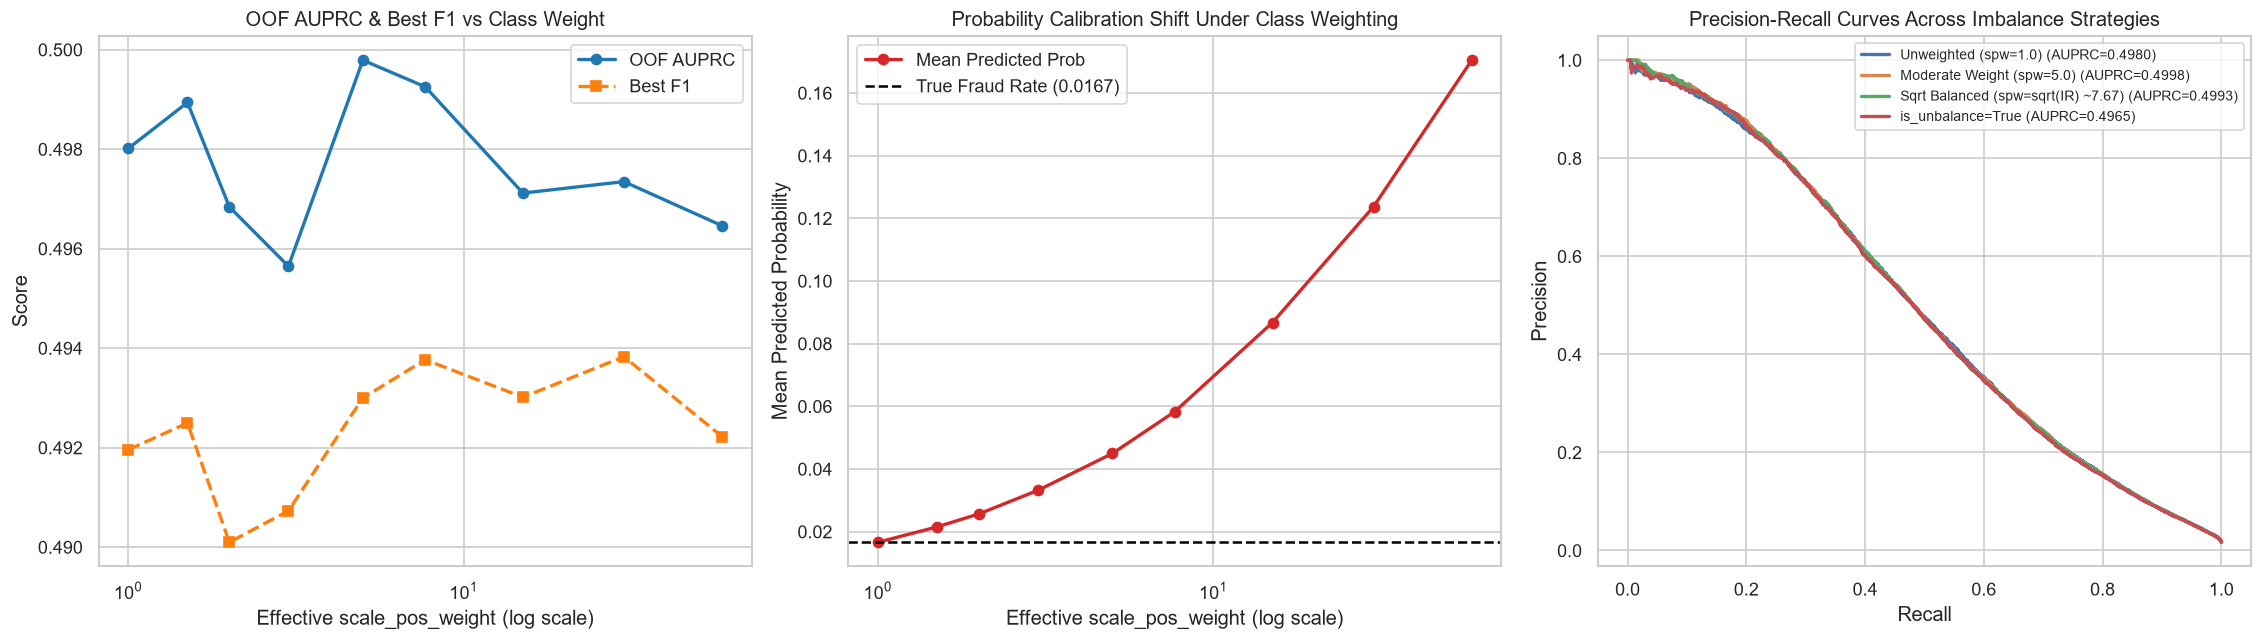

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# Plot 1: OOF AUPRC & Best F1 vs Effective scale_pos_weight (log scale)
plot_df = results_df[results_df["Exp_ID"] != "EXP-2.2"].sort_values("Effective_SPW")
axes[0].plot(plot_df["Effective_SPW"], plot_df["OOF_AUPRC"], marker="o", linewidth=2, label="OOF AUPRC", color="#1f77b4")
axes[0].plot(plot_df["Effective_SPW"], plot_df["Best_F1"], marker="s", linewidth=2, linestyle="--", label="Best F1", color="#ff7f0e")
axes[0].set_xscale("log")
axes[0].set_xlabel("Effective scale_pos_weight (log scale)")
axes[0].set_ylabel("Score")
axes[0].set_title("OOF AUPRC & Best F1 vs Class Weight")
axes[0].legend()

# Plot 2: Probability Calibration Distortion (Mean Predicted Prob vs Base Fraud Rate)
axes[1].plot(plot_df["Effective_SPW"], plot_df["Mean_Pred_Prob"], marker="o", linewidth=2, color="#d62728", label="Mean Predicted Prob")
axes[1].axhline(base_rate, linestyle="--", color="black", label=f"True Fraud Rate ({base_rate:.4f})")
axes[1].set_xscale("log")
axes[1].set_xlabel("Effective scale_pos_weight (log scale)")
axes[1].set_ylabel("Mean Predicted Probability")
axes[1].set_title("Probability Calibration Shift Under Class Weighting")
axes[1].legend()

# Plot 3: Overlaid Precision-Recall Curves for Key Strategies
key_ids = ["EXP-2.1", results_df.iloc[0]["Exp_ID"], "EXP-2.4", "EXP-2.2"]
seen = set()
for exp_id in key_ids:
    if exp_id in seen:
        continue
    seen.add(exp_id)
    row = results_df[results_df["Exp_ID"] == exp_id].iloc[0]
    p, r, _ = precision_recall_curve(y_true, results_store[exp_id]["oof_preds"])
    axes[2].plot(r, p, linewidth=2, label=f"{row['Strategy']} (AUPRC={row['OOF_AUPRC']:.4f})")

axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curves Across Imbalance Strategies")
axes[2].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

## 4. Lock Winning Imbalance Configuration for Task 3 (Optuna Tuning)

In [4]:
best_row = results_df.iloc[0]
baseline_row = results_df[results_df["Exp_ID"] == "EXP-2.1"].iloc[0]

winning_config = {
    "exp_id": str(best_row["Exp_ID"]),
    "strategy": str(best_row["Strategy"]),
    "spw_mode": best_row["spw_mode"] if best_row["spw_mode"] is not None else None,
    "is_unbalance": bool(best_row["is_unbalance"]),
    "effective_spw": float(best_row["Effective_SPW"]),
    "oof_auprc": float(best_row["OOF_AUPRC"]),
    "mean_fold_auprc": float(best_row["Mean_Fold_AUPRC"]),
    "std_fold_auprc": float(best_row["Std_Fold_AUPRC"]),
    "delta_vs_unweighted": float(best_row["OOF_AUPRC"] - baseline_row["OOF_AUPRC"]),
}

with open("lgbm_imbalance_config.json", "w", encoding="utf-8") as f:
    json.dump(winning_config, f, indent=2)

print("Saved winning imbalance configuration -> lgbm_imbalance_config.json")
print(json.dumps(winning_config, indent=2))
print(
    f"\nCoreach.ai Comment -> LGBM Imbalance ({winning_config['strategy']}) "
    f"| CV OOF AUPRC: {winning_config['oof_auprc']:.4f} "
    f"(Delta vs Baseline: {winning_config['delta_vs_unweighted']:+.4f})"
)

Saved winning imbalance configuration -> lgbm_imbalance_config.json
{
  "exp_id": "EXP-2.5d",
  "strategy": "Moderate Weight (spw=5.0)",
  "spw_mode": 5.0,
  "is_unbalance": false,
  "effective_spw": 5.0,
  "oof_auprc": 0.4997888362230191,
  "mean_fold_auprc": 0.5002304368736028,
  "std_fold_auprc": 0.01009722961322005,
  "delta_vs_unweighted": 0.0017741725337291903
}

Coreach.ai Comment -> LGBM Imbalance (Moderate Weight (spw=5.0)) | CV OOF AUPRC: 0.4998 (Delta vs Baseline: +0.0018)
